# Generic Linear MA Trend Following Models

In [85]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm

In [211]:
import sys
sys.path.append(os.path.join(repo_path, "src"))
from SignalFitter import SignalFitter

# Getting Data

In [11]:
program_path = os.getcwd()
res_path     = os.path.abspath(os.path.join(program_path, ".."))
repo_path    = os.path.abspath(os.path.join(res_path, ".."))
data_path    = os.path.join(repo_path, "data", "AllPx")

In [23]:
path = os.path.join(data_path, r"AllProducts.parquet")
df_raw_px = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .rename(columns = {"product": "product_type"})
    .loc[lambda x: x.product_type == "future"]
    .loc[lambda x: x.variable == "fx_adj_px"])

In [24]:
df_px = (df_raw_px
    .drop(columns = ["variable", "product_type"])
    .groupby(["date", "ticker"])
    .agg("mean")
    .reset_index())

# Generic 100 EWMA Signal

In [196]:
df_signal = (df_px
    .pivot(index = "date", columns = "ticker", values = "px")
    .diff()
    .apply(lambda x: x / x.ewm(span = 10, adjust = False).std())
    .apply(lambda x: x.ewm(span = 100, adjust = False).mean())
    .shift()
    .reset_index()
    .melt(id_vars = "date", value_name = "signal")
    .dropna())

In [197]:
df_rtn = (df_px
    .pivot(index = "date", columns = "ticker", values = "px")
    .pct_change()
    .reset_index()
    .melt(id_vars = "date", value_name = "px_rtn")
    .dropna())

In [198]:
df_signal_rtn = (df_signal
    .merge(right = df_rtn, how = "inner", on = ["date", "ticker"])
    .assign(signal_rtn = lambda x: np.sign(x.signal) * x.px_rtn))

In [199]:
df_vol_rtn =  (df_signal_rtn
    .pivot(index = "date", columns = "ticker", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252)))))

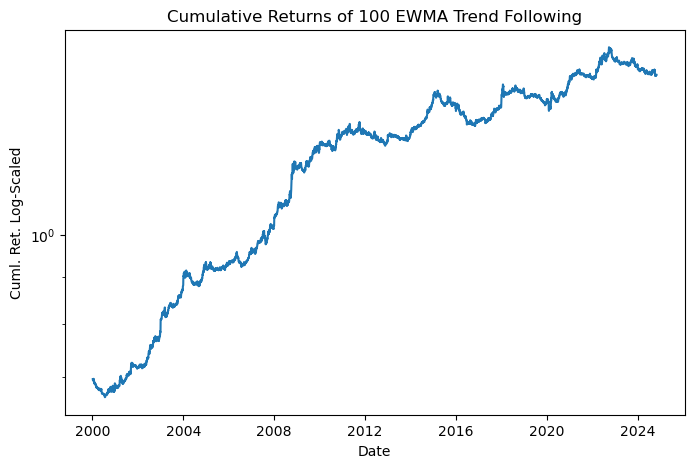

In [200]:
(df_vol_rtn
    .mean(axis = 1)
    .to_frame(name = "Port")
    .apply(lambda x: np.cumprod(1 + x))
    .plot(
        logy    = True,
        legend  = False,
        ylabel  = "Cuml. Ret. Log-Scaled",
        xlabel  = "Date",
        title   = "Cumulative Returns of 100 EWMA Trend Following",
        figsize = (8,5)))

plt.show()

In [204]:
(df_vol_rtn
    .mean(axis = 1)
    .to_frame(name = "tmp")
    .agg(lambda x: x.mean() / x.std() * np.sqrt(252)))

tmp    0.273115
dtype: float64

In [79]:
tickers = (df_signal_rtn
    [["ticker"]]
    .drop_duplicates()
    .ticker
    .drop_duplicates()
    .sort_values()
    .to_list())

func1

In [94]:
window     = 100
model_dict = {}

for ticker in tickers: 

    df_tmp = (df_signal_rtn
        .loc[lambda x: x.ticker == ticker]
        .set_index("date")
        .assign(vol_norm_rtn = lambda x: x.px_rtn / x.px_rtn.ewm(span = window, adjust = False).std()))

    df_sliced = df_tmp.dropna()
    model     = (sm
        .OLS(
            endog = df_sliced.vol_norm_rtn,
            exog  = sm.add_constant(df_sliced.signal))
        .fit())

    model_dict[ticker] = model

func2

In [110]:
df_lists = []

for name in model_dict.keys():

    tmp_name = model_dict[name]
    
    df_param = (tmp_name
        .params
        .to_frame(name = "params")
        .reset_index())

    df_pvalue = (tmp_name
        .pvalues
        .to_frame(name = "pvalue")
        .reset_index())

    df_tvalue = (tmp_name
        .tvalues
        .to_frame(name = "tvalue")
        .reset_index())

    df_add = (df_param
        .merge(right = df_pvalue, how = "inner")
        .merge(right = df_param, how = "inner")
        .merge(right = df_tvalue, how = "inner")
        .assign(ticker = name))
    break

func3

In [120]:
df_signal = (df_px
    .pivot(index = "date", columns = "ticker", values = "px")
    .diff()
    .apply(lambda x: x / x.ewm(span = 10, adjust = False).std())
    .apply(lambda x: x.ewm(span = 100, adjust = False).mean())
    .reset_index()
    .melt(id_vars = "date", value_name = "signal")
    .dropna())

In [125]:
df_decile = (df_signal
    .set_index("date")
    .groupby("ticker")
    .apply(lambda x: pd.qcut(x = x.signal, q = 10, labels = [i + 1 for i in range(10)]).shift())
    .to_frame(name = "decile")
    .reset_index())

In [133]:
df_vol_rtn = (df_rtn
    .pivot(index = "date", columns = "ticker", values = "px_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std())))
    .reset_index()
    .melt(id_vars = "date", value_name = "vol_rtn")
    .dropna())

In [137]:
df_decile_rtn = (df_decile
    .merge(right = df_vol_rtn, how = "inner", on = ["date", "ticker"])
    .dropna())

In [142]:
df_decile_sharpe = (df_decile_rtn
    .drop(columns = ["date"])
    .groupby(["ticker", "decile"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(252))
    .reset_index()
    .rename(columns = {"vol_rtn": "sharpe"}))

In [146]:
df_decile_sliced = (df_decile_sharpe
    .loc[lambda x: x.decile.isin([1,2,9,10])]
    .assign(group_var = lambda x: np.where(x.decile <= 2, "lgroup", "ugroup")))

In [158]:
df_signal_scaler = (df_decile_sliced
    .drop(columns = ["decile"])
    .groupby(["ticker", "group_var"])
    .agg("prod")
    .reset_index()
    .assign(signal_scaler = lambda x: np.where(x.sharpe > 0, 1, np.nan))
    .drop(columns = ["sharpe"]))

In [168]:
df_opt_rtn = (df_decile_rtn
    .drop(columns = ["vol_rtn"])
    .merge(right = df_rtn, how = "inner", on = ["date", "ticker"])
    .merge(right = df_decile_sliced, how = "inner", on = ["ticker", "decile"])
    .merge(right = df_signal_scaler, how = "inner", on = ["ticker", "group_var"]))

In [178]:
df_mean = (df_opt_rtn
    .assign(signal_rtn = lambda x: np.sign(x.sharpe) * x.signal_scaler * x.px_rtn)
    .pivot(index = "date", columns = "ticker", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
    .mean(axis = 1)
    .to_frame(name = "tmp"))

In [182]:
df_mean.agg(lambda x: x.mean() / x.std() * np.sqrt(252))

tmp    0.588964
dtype: float64

<Axes: xlabel='date'>

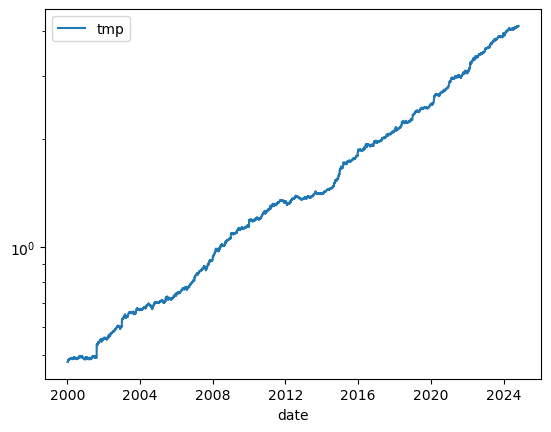

In [185]:
df_mean.apply(lambda x: np.cumprod(1 + x)).plot(logy = True)

In [188]:
df_mean.mean() / df_mean.std() * np.sqrt(252)

tmp    0.588964
dtype: float64

In [210]:
df_combined = (df_signal
    .merge(right = df_rtn, how = "inner", on = ["date", "ticker"]))

In [217]:
insample_models = SignalFitter().fit_full_sample(df_combined)
insample_params = SignalFitter().get_full_sample_params(insample_models)